# 04. Comparación de movilidad durante incidencias de Rodalies

Se analizan **tres incidencias** mediante un único procedimiento: **7 de febrero (R1/Maresme), 17 de marzo (Vallès) y 5 de junio de 2025 (corredor sur)**. Cada caso genera las mismas tablas, gráficos, indicadores y estructura JSON. Solo varían la incidencia documentada y los municipios del ámbito de estudio.

**Método:** para cada relación OD se compara el viaje observado con la **mediana de viajes observados de los mismos días de la semana dentro de ±42 días**, excluyendo festivos y fechas con incidencias registradas. No se utiliza regresión ni se imputan ausencias. Una mediana nula no permite calcular un porcentaje válido.

$$\text{Variación (\%)}=100\left(\frac{\text{viajes observados}}{\text{mediana de viajes comparables}}-1\right)$$

Este análisis es descriptivo, integra desplazamientos de todos los modos y **no identifica efectos causales de Rodalies ni el transporte utilizado**.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import duckdb
import holidays
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "data/processed/telefonica/M2.parquet").is_file())
DATA_DIR = PROJECT_ROOT / "data"
M2_PATH = DATA_DIR / "processed/telefonica/M2.parquet"
INCIDENCIAS_PATH = DATA_DIR / "raw/rodalies/RMOVE_Incidencias_Barcelona_Jul2024_Ago2025_v07.xlsx"
con = duckdb.connect()
festivos_cat = holidays.country_holidays("ES", subdiv="CT", years=[2023, 2024, 2025])
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from analysis.rmove_general import cargar_catalogo
from analysis.rmove_indicators import (
    cargar_relaciones, calcular_indicadores, comparar_relaciones,
    seleccionar_controles, evaluar_mediana, MESES_EXCLUIDOS,
)
print("M2 encontrado:", M2_PATH.exists(), "| Excel encontrado:", INCIDENCIAS_PATH.exists())
from analysis.rmove_cases import (
    ficha_incidencia, evaluar_disponibilidad, analizar_robustez,
    conclusiones_caso, exportar_caso,
)

M2 encontrado: True | Excel encontrado: True


## 1. Registro y casos seleccionados

La fuente de las fechas, líneas afectadas y descripciones es el Excel de incidencias. Conservamos **todas las fechas del registro** para excluirlas de los controles, incluso cuando no son casos principales.

In [2]:
incidencias = cargar_catalogo(INCIDENCIAS_PATH)
fechas_con_incidencias = set(incidencias["date"].dt.normalize().dropna())

CASOS = [
    {
        "id": "172",
        "ambito": "R1 / Maresme",
        "municipios": [
            {"codigo": "08019", "nombre": "Barcelona", "lat": 41.387, "lon": 2.170},
            {"codigo": "08121", "nombre": "Mataró", "lat": 41.538, "lon": 2.445},
            {"codigo": "08172", "nombre": "Premià de Mar", "lat": 41.491, "lon": 2.357},
            {"codigo": "08118", "nombre": "El Masnou", "lat": 41.479, "lon": 2.317},
            {"codigo": "08006", "nombre": "Arenys de Mar", "lat": 41.581, "lon": 2.551},
        ],
    },
    {
        "id": "203",
        "ambito": "Vallès",
        "municipios": [
            {"codigo": "08019", "nombre": "Barcelona", "lat": 41.387, "lon": 2.170},
            {"codigo": "08125", "nombre": "Montcada i Reixac", "lat": 41.486, "lon": 2.188},
            {"codigo": "08266", "nombre": "Cerdanyola del Vallès", "lat": 41.491, "lon": 2.140},
            {"codigo": "08187", "nombre": "Sabadell", "lat": 41.548, "lon": 2.108},
            {"codigo": "08279", "nombre": "Terrassa", "lat": 41.563, "lon": 2.009},
        ],
    },
    
    {
    "id": "248",
    "ambito": "Barcelona y corredores R1/RG1, R3 y R4",
    "municipios": [
        {"codigo": "08019", "nombre": "Barcelona", "lat": 41.387, "lon": 2.170},
        {"codigo": "08194", "nombre": "Sant Adrià de Besòs", "lat": 41.430, "lon": 2.218},
        {"codigo": "08015", "nombre": "Badalona", "lat": 41.450, "lon": 2.247},
        {"codigo": "08126", "nombre": "Montgat", "lat": 41.468, "lon": 2.280},
        {"codigo": "08118", "nombre": "El Masnou", "lat": 41.479, "lon": 2.319},
        {"codigo": "08172", "nombre": "Premià de Mar", "lat": 41.492, "lon": 2.365},
        {"codigo": "08219", "nombre": "Vilassar de Mar", "lat": 41.505, "lon": 2.393},
        {"codigo": "08121", "nombre": "Mataró", "lat": 41.540, "lon": 2.445},
        {"codigo": "08125", "nombre": "Montcada i Reixac", "lat": 41.484, "lon": 2.187},
        {"codigo": "08260", "nombre": "Santa Perpètua de Mogoda", "lat": 41.535, "lon": 2.179},
        {"codigo": "08124", "nombre": "Mollet del Vallès", "lat": 41.540, "lon": 2.213},
        {"codigo": "08159", "nombre": "Parets del Vallès", "lat": 41.574, "lon": 2.233},
        {"codigo": "08096", "nombre": "Granollers", "lat": 41.608, "lon": 2.288},
        {"codigo": "08266", "nombre": "Cerdanyola del Vallès", "lat": 41.491, "lon": 2.140},
        {"codigo": "08252", "nombre": "Barberà del Vallès", "lat": 41.516, "lon": 2.124},
        {"codigo": "08187", "nombre": "Sabadell", "lat": 41.546, "lon": 2.108},
        {"codigo": "08279", "nombre": "Terrassa", "lat": 41.563, "lon": 2.010},
        {"codigo": "08101", "nombre": "L'Hospitalet de Llobregat", "lat": 41.359, "lon": 2.100},
        {"codigo": "08073", "nombre": "Cornellà de Llobregat", "lat": 41.355, "lon": 2.070},
        {"codigo": "08217", "nombre": "Sant Joan Despí", "lat": 41.367, "lon": 2.057},
        {"codigo": "08211", "nombre": "Sant Feliu de Llobregat", "lat": 41.381, "lon": 2.045},
        {"codigo": "08123", "nombre": "Molins de Rei", "lat": 41.415, "lon": 2.015},
        {"codigo": "08114", "nombre": "Martorell", "lat": 41.474, "lon": 1.931}
    ]
    },

    
    {
        "id": "16",
        "ambito": "Corredor sur",
        "municipios": [
            {"codigo": "08019", "nombre": "Barcelona", "lat": 41.383, "lon": 2.177},
            {"codigo": "08169", "nombre": "El Prat de Llobregat", "lat": 41.327, "lon": 2.095},
            {"codigo": "08307", "nombre": "Vilanova i la Geltrú", "lat": 41.224, "lon": 1.726},
            {"codigo": "08089", "nombre": "Gavà", "lat": 41.304, "lon": 1.999},
            {"codigo": "08056", "nombre": "Castelldefels", "lat": 41.281, "lon": 1.976},
        ],
    },
    {
        "id": "67",
        "ambito": "Corredor nord",
        "municipios": [
            {"codigo": "08124", "nombre": "Mollet del Vallès", "lat": 41.536, "lon": 2.210},
            {"codigo": "08125", "nombre": "Montcada i Reixac", "lat": 41.480, "lon": 2.187},
            {"codigo": "08135", "nombre": "Montmeló", "lat": 41.552, "lon": 2.248},
            {"codigo": "08096", "nombre": "Granollers", "lat": 41.608, "lon": 2.287},
            {"codigo": "08105", "nombre": "La Llagosta", "lat": 41.514, "lon": 2.193},
        ],
    },
]

fichas = {caso["id"]: ficha_incidencia(incidencias, caso["id"]) for caso in CASOS}
ids_seleccionados = [caso["id"] for caso in CASOS]
display(incidencias.loc[incidencias["incident_id"].isin(ids_seleccionados),
    ["incident_id", "date", "line", "place", "incident_type",
     "description", "schedule / duration", "notes", "URL"]].sort_values("date"))
output_dir = PROJECT_ROOT / "data/processed/rmove"

,incident_id,date,line,place,incident_type,description,schedule / duration,notes,URL
21,16,2023-05-02,R2 Sud; R13; R14; R15; R16; R17,El Prat de Llobregat–Castelldefels,Avería del sistema de señalización de Gavà,Retrasos importantes y reprogramación del serv...,06:59 h (publicación de la noticia),NaN,https://www.3cat.cat/3catinfo/retards-a-lr2-su...
104,67,2024-04-29,R2; R2 Nord; R8; R11,Mollet-Sant Fost–Montmeló,Robo masivo de cobre,Sustracción de cableado que inutilizó los circ...,05:45–11:00 h,Retrasos hacia Girona y el Aeropuerto.,https://www.3cat.cat/3catinfo/un-robatori-de-c...
215,172,2025-02-07,R1; R3; R4; R7,Barcelona-Sants–Plaça de Catalunya,Avería de señalización,Circulación por vía única durante casi cinco h...,Desde primera hora hasta pasadas 10:00,Informe parlamentario de incidencia destacada:...,https://www.3cat.cat/3catinfo/retards-a-les-li...
246,203,2025-03-17,Todas,Cataluña,Conflictividad laboral / desconvocatoria tardía,Supresiones y demoras generalizadas tras desco...,Desde comienzo del servicio,Informe parlamentario contabiliza 78.470 viaje...,https://rodalies.gencat.cat/web/.content/06_At...
291,248,2025-06-05,R1; R3; R4; RG1,Arc de Triomf,Avería técnica de tren,Tren averiado; desvíos y estaciones sin parada...,14:45–16:20,NaN,https://rodalies.gencat.cat/web/.content/06_At...


## 2. Funciones comunes

**El mismo proceso** selecciona OD, comprueba disponibilidad, calcula medianas y variaciones, muestra las mismas tablas y gráficos, evalúa cobertura y robustez, y exporta el JSON para las tres fechas. No se introducen bloques específicos de cálculo por incidencia.

In [3]:
def cargar_od(origen, destino, nombre):
    return cargar_relaciones(con, M2_PATH, {nombre: (origen, destino)})

def cargar_totales(fecha, ventana=56):
    datos = con.execute("""
        SELECT day, SUM(viajes) AS viajes_observados,
               COUNT(*) AS registros, AVG(viajes) AS viajes_por_registro,
               COUNT(DISTINCT (municipio_origen, municipio_destino)) AS n_od
        FROM read_parquet(?) WHERE day BETWEEN ? AND ?
        AND municipio_origen<>municipio_destino GROUP BY day ORDER BY day
    """, [str(M2_PATH), (fecha-pd.Timedelta(days=ventana)).date(),
          (fecha+pd.Timedelta(days=ventana)).date()]).df()
    datos["day"] = pd.to_datetime(datos["day"])
    return datos

def tabla_cobertura(datos, fecha):
    controles = seleccionar_controles(datos, fecha, fechas_con_incidencias, festivos_cat)
    dia = datos.loc[datos["day"].eq(fecha)]
    if dia.empty or controles.empty:
        return pd.DataFrame()
    filas = []
    for campo in ["viajes_observados", "registros", "n_od", "viajes_por_registro"]:
        observado = dia[campo].iloc[0]
        mediana = controles[campo].median()
        filas.append({"Indicador": campo, "Observado": observado, "Mediana controles": mediana,
                      "Variacion (%)": 100*(observado/mediana-1) if mediana>0 else np.nan,
                      "N controles": len(controles)})
    return pd.DataFrame(filas)
def graficar_variacion(tabla, titulo, alto=7):
    orden = tabla.sort_values("variacion_observada_pct")
    fig, ax = plt.subplots(figsize=(12, alto))
    ax.barh(orden["Relacion"], orden["variacion_observada_pct"],
            color=["#b64026" if v<0 else "#087e86" for v in orden["variacion_observada_pct"]])
    ax.axvline(0, color="black", linewidth=1)
    ax.set(xlabel="Variación de viajes frente a la mediana (%)", ylabel="", title=titulo)
    ax.invert_yaxis(); ax.grid(axis="x", alpha=.25)
    plt.tight_layout(); plt.show()

def graficar_cobertura(datos, fecha, titulo):
    comparables = seleccionar_controles(datos, fecha, fechas_con_incidencias, festivos_cat)
    dias = datos.loc[datos["day"].dt.day_of_week.eq(fecha.day_of_week)]
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    for ax, campo in zip(axes, ["viajes_observados", "registros", "n_od"]):
        ax.plot(dias["day"], dias[campo], color="#798b96", marker="o", label="Mismo día semanal")
        ax.scatter(comparables["day"], comparables[campo], color="#087e86", label="Controles usados")
        ax.axvline(fecha, color="#e8700a", linestyle="--", label="Incidencia")
        ax.set_ylabel(campo); ax.grid(alpha=.25)
    axes[0].set_title(titulo); axes[0].legend()
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

def graficar_evolucion(movilidad, fecha, nombres):
    fig, axes = plt.subplots(len(nombres), 1, figsize=(12, 4*len(nombres)), sharex=True, squeeze=False)
    for ax, nombre in zip(axes[:, 0], nombres):
        grupo = movilidad.loc[movilidad["Relacion"].eq(nombre)].sort_values("day")
        dias = pd.date_range(fecha-pd.Timedelta(days=21), fecha+pd.Timedelta(days=21))
        refs = pd.DataFrame([calcular_indicadores(grupo, d, fechas_con_incidencias, festivos_cat)[0] for d in dias])
        medianas = refs["mediana_viajes_controles"].where(refs["estado"].eq("ok"))
        ax.plot(dias, refs["viajes_observados"], label="Observados", marker="o", markersize=3)
        ax.plot(dias, medianas, linestyle="--", label="Mediana retrospectiva")
        ax.axvline(fecha, color="#e8700a", linestyle=":")
        ax.set(title=nombre, ylabel="Viajes"); ax.legend(); ax.grid(alpha=.25)
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [4]:
def preparar_relaciones(caso, fecha):
    municipios = {m["codigo"]: m["nombre"] for m in caso["municipios"]}
    relaciones = {
        f"{nombre_o} → {nombre_d}": (codigo_o, codigo_d)
        for codigo_o, nombre_o in municipios.items()
        for codigo_d, nombre_d in municipios.items()
        if codigo_o != codigo_d
    }
    movilidad_candidata = cargar_relaciones(con, M2_PATH, relaciones)
    disponibilidad = evaluar_disponibilidad(
        movilidad_candidata, relaciones, fecha, fechas_con_incidencias, festivos_cat
    )
    seleccionadas = disponibilidad.loc[disponibilidad["seleccionada"], "Relacion"]
    movilidad = movilidad_candidata.loc[
        movilidad_candidata["Relacion"].isin(seleccionadas)
    ].copy()
    return relaciones, disponibilidad, movilidad



def mostrar_seleccion(disponibilidad, numero_municipios, fecha, relaciones):
    n_validas = int(disponibilidad["seleccionada"].sum())
    n_excluidas = len(relaciones) - n_validas

    print(f"Fecha: {fecha:%d/%m/%Y}")
    print(f"Municipios: {numero_municipios}")
    print(f"Relaciones analizadas: {n_validas}/{len(relaciones)}")

    if n_excluidas:
        print(f"Relaciones excluidas: {n_excluidas}")




def mostrar_resultados(resultados, titulo):
    validas = resultados.dropna(
        subset=["variacion_observada_pct"]
    ).sort_values("variacion_observada_pct")

    if validas.empty:
        print("No hay relaciones con variación calculable.")
        return

    mayor_caida = validas.iloc[0]
    mayor_aumento = validas.iloc[-1]

    print(f"\nRESULTADOS · {titulo}")
    print(
        f"Mayor disminución: {mayor_caida['Relacion']} "
        f"({mayor_caida['variacion_observada_pct']:+.2f}%)"
    )
    print(
        f"Mayor aumento: {mayor_aumento['Relacion']} "
        f"({mayor_aumento['variacion_observada_pct']:+.2f}%)"
    )

    graficar_variacion(validas, titulo, alto=8)




def ejecutar_caso(caso):
    ficha = fichas[caso["id"]]
    fecha = pd.Timestamp(ficha["fecha"])
    titulo = f"{fecha:%d/%m/%Y} · {caso['ambito']}"

    print(f"\n{'=' * 60}")
    print(f"CASO {caso['id']} · {titulo}")
    print(f"{'=' * 60}")

    # 1. Selección de relaciones
    relaciones, disponibilidad, movilidad = preparar_relaciones(
        caso, fecha
    )

    mostrar_seleccion(
        disponibilidad,
        len(caso["municipios"]),
        fecha,
        relaciones
    )

    if not disponibilidad["seleccionada"].any():
        raise ValueError(
            f"{caso['id']}: ninguna relación cumple "
            "los criterios de disponibilidad"
        )

    # 2. Calcular resultados
    resultados = comparar_relaciones(
        movilidad,
        fecha,
        fechas_con_incidencias,
        festivos_cat
    )

    # 3. Mostrar únicamente el resumen y el gráfico
    mostrar_resultados(resultados, titulo)

    # 4. Calcular cobertura, robustez y sensibilidad
    # Sin mostrar tablas intermedias
    provincial = cargar_totales(fecha)
    cobertura = tabla_cobertura(provincial, fecha)

    predictivo, robustez, sensibilidad = analizar_robustez(
        movilidad,
        fecha,
        fechas_con_incidencias,
        festivos_cat,
        resultados
    )

    # 5. Conclusiones
    print(f"\nCONCLUSIONES · {titulo}")

    for conclusion in conclusiones_caso(resultados, cobertura):
        print(f"• {conclusion}")

    # 6. Exportar todos los resultados
    catalogo = [
        {
            **m,
            "precision": (
                "Posición municipal aproximada; "
                "no es una estación"
            )
        }
        for m in caso["municipios"]
    ]

    salida = exportar_caso(
        output_dir=output_dir,
        fecha=fecha,
        ficha=ficha,
        ambito=caso["ambito"],
        municipios=catalogo,
        resultados=resultados,
        movilidad=movilidad,
        disponibilidad=disponibilidad,
        provincia=provincial,
        cobertura=cobertura,
        robustez=robustez,
        sensibilidad=sensibilidad,
        fechas_incidencias=fechas_con_incidencias,
        festivos=festivos_cat,
        fuente_excel=str(
            INCIDENCIAS_PATH.relative_to(PROJECT_ROOT)
        ),
    )

    print(f"\nJSON guardado: incidencia_{fecha:%Y_%m_%d}.json")

    return {
        "fecha": fecha,
        "ficha": ficha,
        "movilidad": movilidad,
        "disponibilidad": disponibilidad,
        "resultados": resultados,
        "provincial": provincial,
        "cobertura": cobertura,
        "predictivo": predictivo,
        "robustez": robustez,
        "sensibilidad": sensibilidad,
        "salida": salida
    }



## 3. Caso 1: 7 de febrero de 2025 · R1 / Maresme

Este caso ejecuta **exactamente el mismo procedimiento** que los otros dos. El ámbito, la fecha y la información documental se toman de la configuración y del Excel. Los resultados y la exportación se generan automáticamente a partir de los datos, sin conclusiones numéricas escritas manualmente.


CASO 172 · 07/02/2025 · R1 / Maresme
Fecha: 07/02/2025
Municipios: 5
Relaciones analizadas: 18/20
Relaciones excluidas: 2

RESULTADOS · 07/02/2025 · R1 / Maresme
Mayor disminución: Mataró → El Masnou (-13.34%)
Mayor aumento: Arenys de Mar → Premià de Mar (+26.09%)


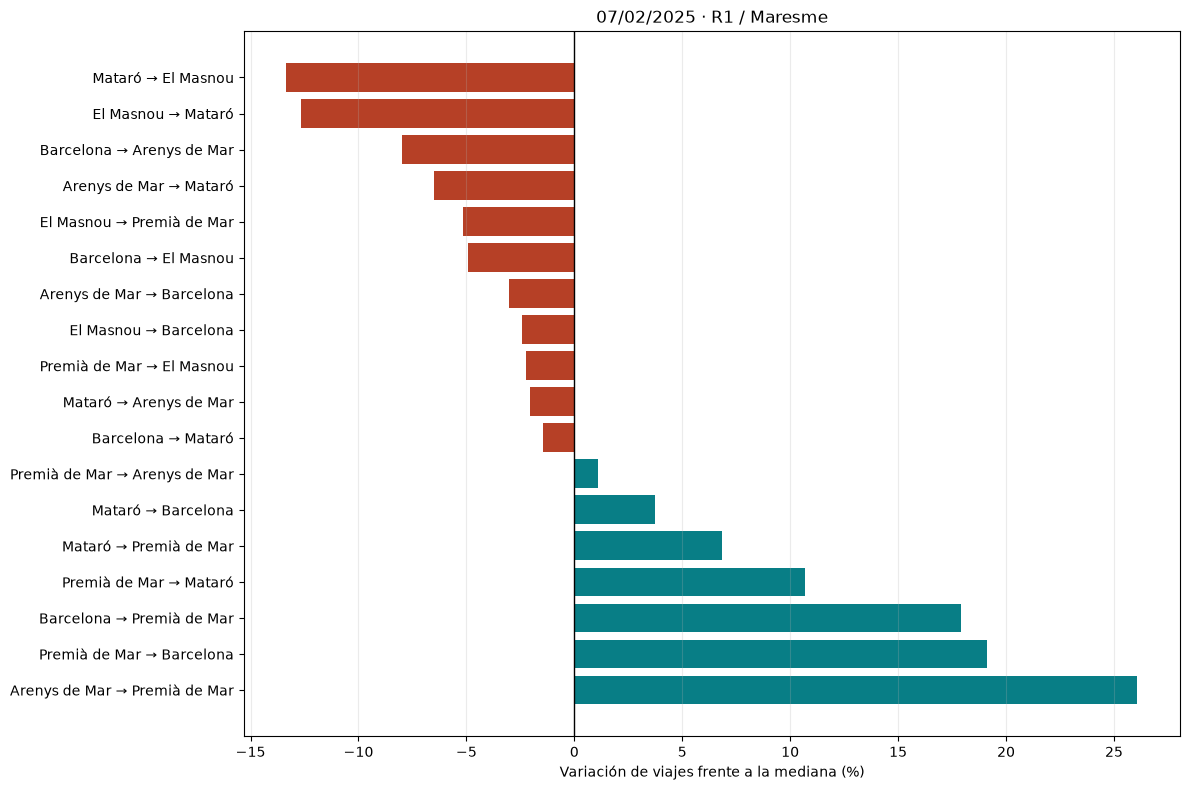


CONCLUSIONES · 07/02/2025 · R1 / Maresme
• 18 relaciones con comparación válida: 11 por debajo de la mediana y 7 por encima.
• Menor variación: Mataró → El Masnou (-13,34 %).
• Mayor variación: Arenys de Mar → Premià de Mar (+26,09 %).
• Variación de viajes provinciales frente a sus días comparables: +0,34 %.
• Variación de registros de movilidad frente a sus días comparables: +0,21 %.
• Las cifras son diferencias descriptivas frente a días comparables. No demuestran efectos causales de Rodalies ni validan un detector de incidencias.

JSON guardado: incidencia_2025_02_07.json


In [5]:
caso_1 = ejecutar_caso(CASOS[0])

## 4. Caso 2: 17 de marzo de 2025 · Vallès

Este caso ejecuta **exactamente el mismo procedimiento** que los otros dos. El ámbito, la fecha y la información documental se toman de la configuración y del Excel. Los resultados y la exportación se generan automáticamente a partir de los datos, sin conclusiones numéricas escritas manualmente.


CASO 203 · 17/03/2025 · Vallès
Fecha: 17/03/2025
Municipios: 5
Relaciones analizadas: 20/20

RESULTADOS · 17/03/2025 · Vallès
Mayor disminución: Cerdanyola del Vallès → Montcada i Reixac (-7.57%)
Mayor aumento: Montcada i Reixac → Barcelona (+37.48%)


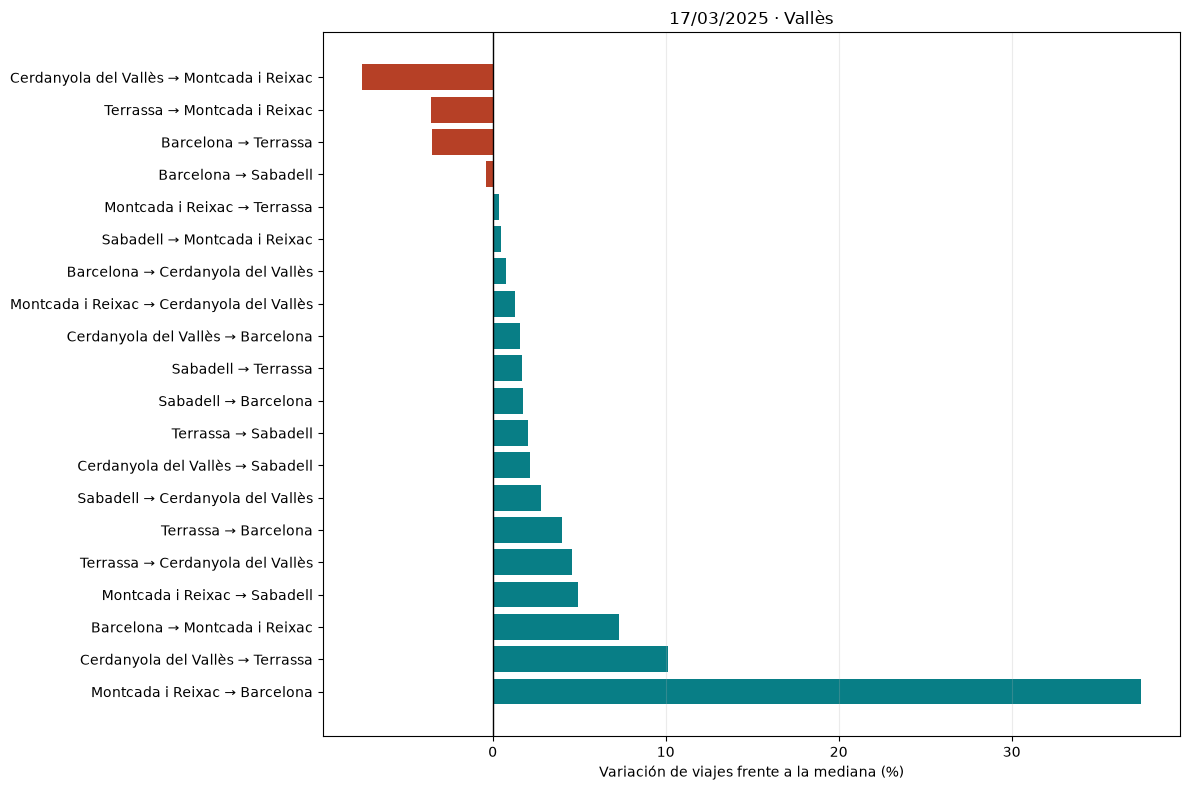


CONCLUSIONES · 17/03/2025 · Vallès
• 20 relaciones con comparación válida: 4 por debajo de la mediana y 16 por encima.
• Menor variación: Cerdanyola del Vallès → Montcada i Reixac (-7,57 %).
• Mayor variación: Montcada i Reixac → Barcelona (+37,48 %).
• Variación de viajes provinciales frente a sus días comparables: +2,34 %.
• Variación de registros de movilidad frente a sus días comparables: +1,56 %.
• Las cifras son diferencias descriptivas frente a días comparables. No demuestran efectos causales de Rodalies ni validan un detector de incidencias.

JSON guardado: incidencia_2025_03_17.json


In [6]:
caso_2 = ejecutar_caso(CASOS[1])

## 5. Caso 3: 5 de junio de 2025 · Corredor sur

Este caso ejecuta **exactamente el mismo procedimiento** que los otros dos. El ámbito, la fecha y la información documental se toman de la configuración y del Excel. Los resultados y la exportación se generan automáticamente a partir de los datos, sin conclusiones numéricas escritas manualmente.


CASO 248 · 05/06/2025 · Barcelona y corredores R1/RG1, R3 y R4
Fecha: 05/06/2025
Municipios: 23
Relaciones analizadas: 349/506
Relaciones excluidas: 157

RESULTADOS · 05/06/2025 · Barcelona y corredores R1/RG1, R3 y R4
Mayor disminución: Martorell → Barberà del Vallès (-35.40%)
Mayor aumento: Badalona → Sant Feliu de Llobregat (+57.66%)


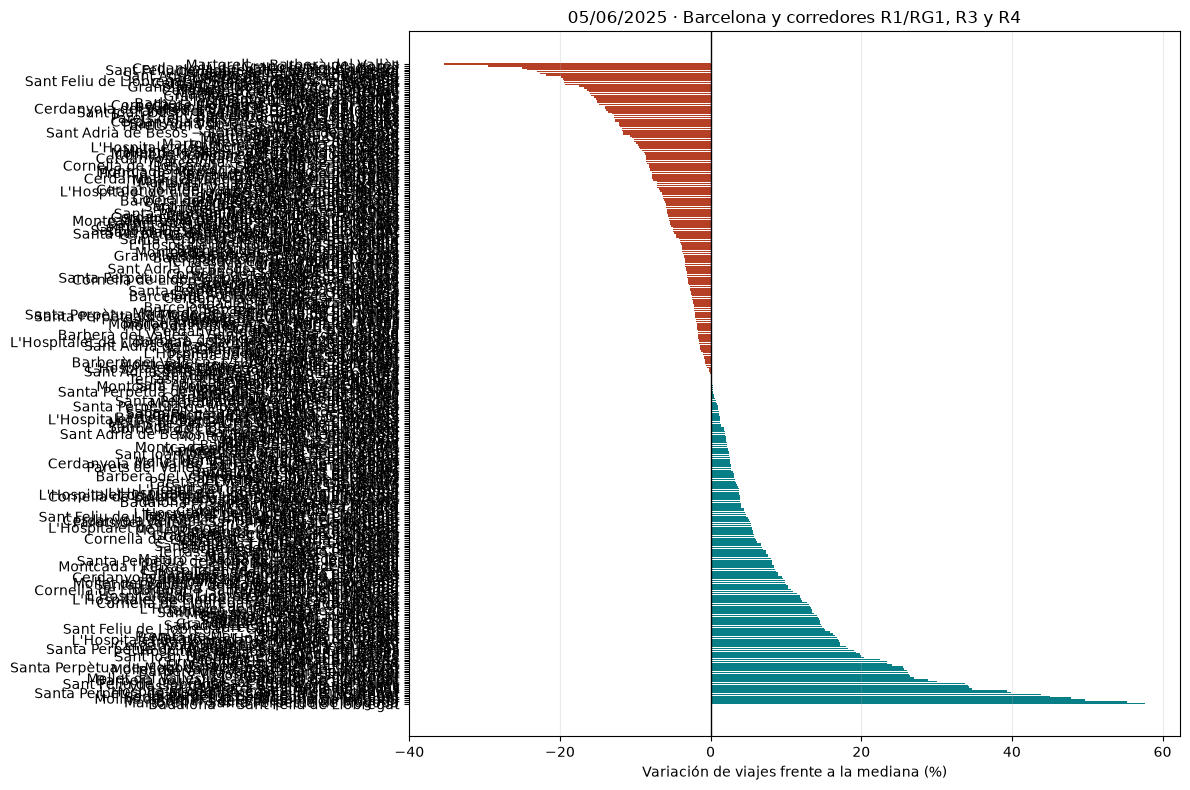


CONCLUSIONES · 05/06/2025 · Barcelona y corredores R1/RG1, R3 y R4
• 349 relaciones con comparación válida: 169 por debajo de la mediana y 178 por encima.
• Menor variación: Martorell → Barberà del Vallès (-35,40 %).
• Mayor variación: Badalona → Sant Feliu de Llobregat (+57,66 %).
• Variación de viajes provinciales frente a sus días comparables: -1,99 %.
• Variación de registros de movilidad frente a sus días comparables: -1,34 %.
• Las cifras son diferencias descriptivas frente a días comparables. No demuestran efectos causales de Rodalies ni validan un detector de incidencias.

JSON guardado: incidencia_2025_06_05.json


In [7]:
caso_3 = ejecutar_caso(CASOS[2])


CASO 16 · 02/05/2023 · Corredor sur
Fecha: 02/05/2023
Municipios: 5
Relaciones analizadas: 20/20

RESULTADOS · 02/05/2023 · Corredor sur
Mayor disminución: Vilanova i la Geltrú → Barcelona (-32.15%)
Mayor aumento: Gavà → Vilanova i la Geltrú (+109.46%)


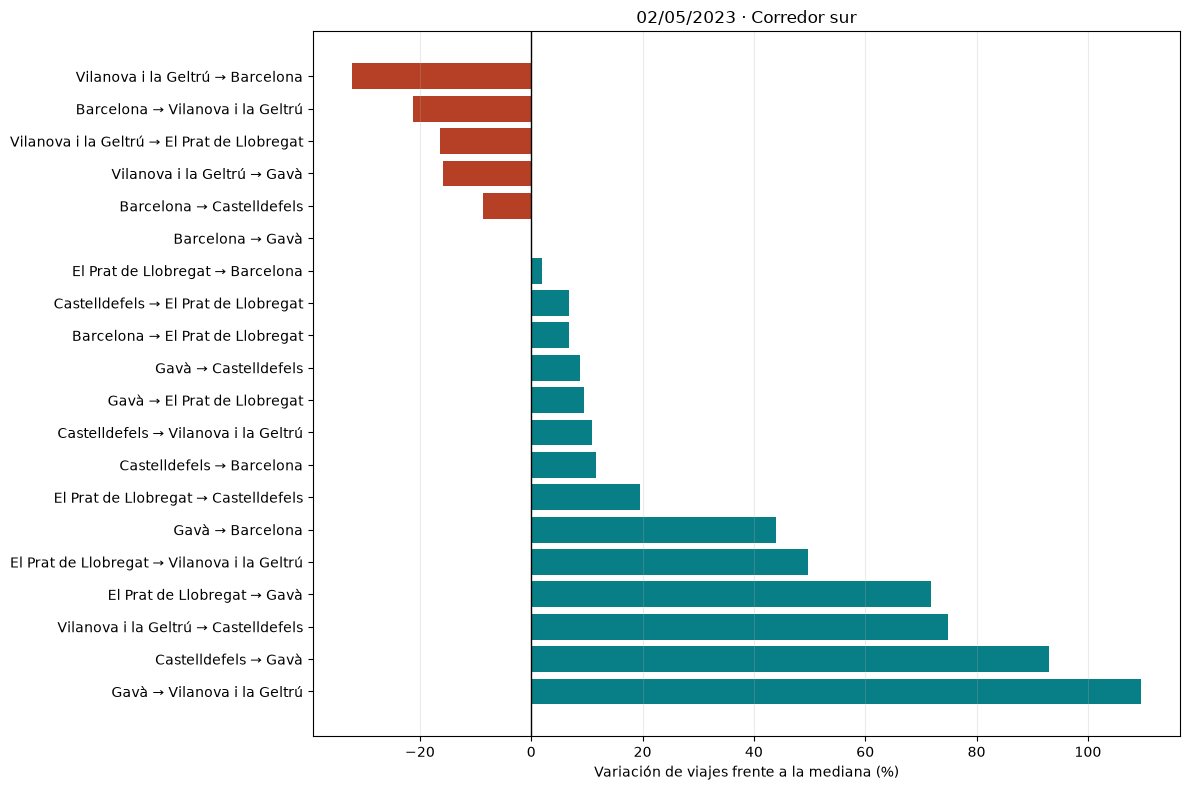


CONCLUSIONES · 02/05/2023 · Corredor sur
• 20 relaciones con comparación válida: 5 por debajo de la mediana y 15 por encima.
• Menor variación: Vilanova i la Geltrú → Barcelona (-32,15 %).
• Mayor variación: Gavà → Vilanova i la Geltrú (+109,46 %).
• Variación de viajes provinciales frente a sus días comparables: +2,30 %.
• Variación de registros de movilidad frente a sus días comparables: +1,32 %.
• Las cifras son diferencias descriptivas frente a días comparables. No demuestran efectos causales de Rodalies ni validan un detector de incidencias.

JSON guardado: incidencia_2023_05_02.json


In [8]:
caso_4 = ejecutar_caso(CASOS[3])


CASO 67 · 29/04/2024 · Corredor nord
Fecha: 29/04/2024
Municipios: 5
Relaciones analizadas: 18/20
Relaciones excluidas: 2

RESULTADOS · 29/04/2024 · Corredor nord
Mayor disminución: Mollet del Vallès → La Llagosta (-2.43%)
Mayor aumento: Montcada i Reixac → La Llagosta (+58.60%)


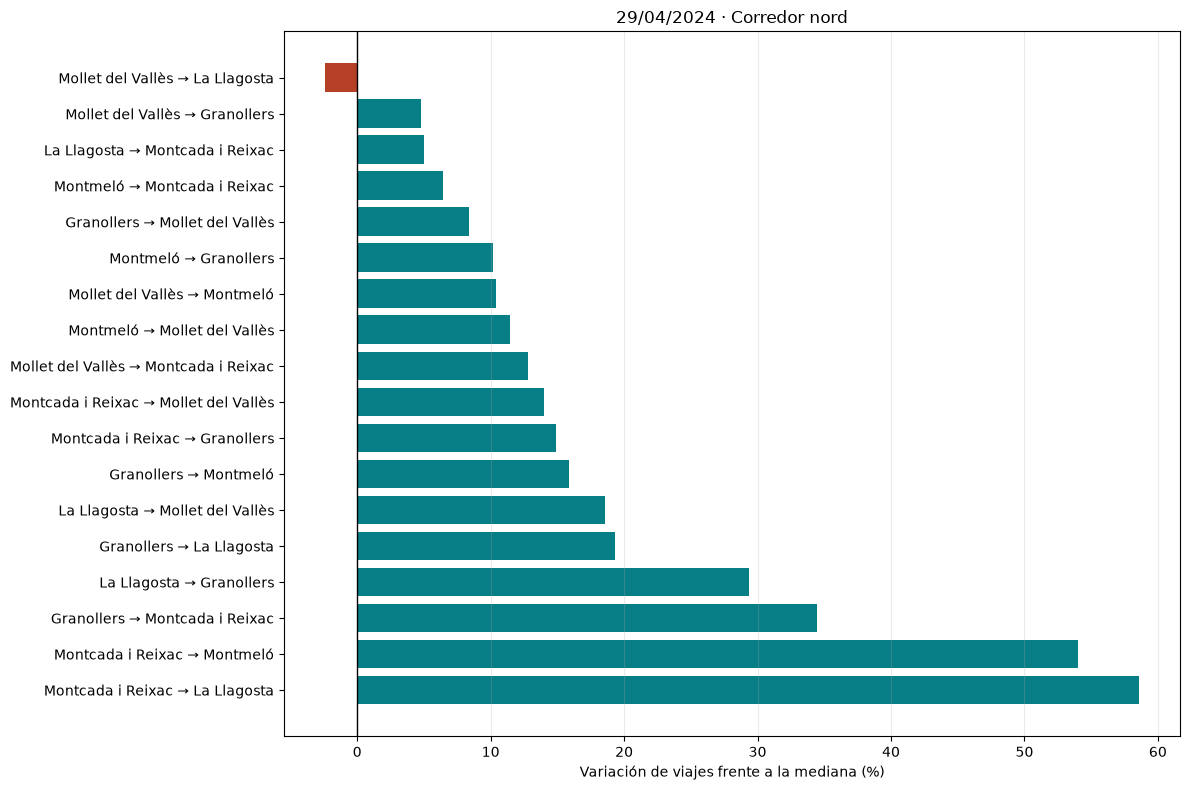


CONCLUSIONES · 29/04/2024 · Corredor nord
• 18 relaciones con comparación válida: 1 por debajo de la mediana y 17 por encima.
• Menor variación: Mollet del Vallès → La Llagosta (-2,43 %).
• Mayor variación: Montcada i Reixac → La Llagosta (+58,60 %).
• Variación de viajes provinciales frente a sus días comparables: -1,67 %.
• Variación de registros de movilidad frente a sus días comparables: -5,10 %.
• Las cifras son diferencias descriptivas frente a días comparables. No demuestran efectos causales de Rodalies ni validan un detector de incidencias.

JSON guardado: incidencia_2024_04_29.json


In [9]:
caso_5 = ejecutar_caso(CASOS[4])

## 6. Comparación final de los tres casos

La tabla siguiente resume los resultados obtenidos ejecutando **el mismo método** en las tres fechas. La existencia de una incidencia ferroviaria no demuestra que haya causado las variaciones observadas.

In [ ]:
resumen_casos = []
for caso_cfg, caso_res in zip(CASOS, [caso_1, caso_2, caso_3]):
    tabla = caso_res["resultados"]
    variaciones = pd.to_numeric(tabla["variacion_observada_pct"], errors="coerce").dropna()
    resumen_casos.append({
        "Incidencia": caso_cfg["id"],
        "Fecha": caso_res["fecha"].strftime("%d/%m/%Y"),
        "Ámbito": caso_cfg["ambito"],
        "OD seleccionadas": len(tabla),
        "OD con variación calculable": len(variaciones),
        "OD con descenso": int((variaciones < 0).sum()),
        "OD con aumento": int((variaciones > 0).sum()),
        "Mediana variación OD (%)": variaciones.median() if len(variaciones) else np.nan,
    })
display(pd.DataFrame(resumen_casos).round(2))